In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!


In [57]:
import zipfile
import os

zip_path = "/content/archive (1) (1).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/customer_data")

print("Extracted files:")
print(os.listdir("/content/customer_data"))

Extracted files:
['Mall_Customers.csv']


In [58]:
import pandas as pd

df = pd.read_csv("/content/customer_data/Mall_Customers.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [59]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [60]:
# Select important features
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

print("Selected customer features:")
display(X.head())

print("\nStatistical summary:")
display(X.describe())

Selected customer features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Statistical summary:


,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000
mean,60.560000,50.200000
std,26.264721,25.823522
min,15.000000,1.000000
25%,41.500000,34.750000
50%,61.500000,50.000000
75%,78.000000,73.000000
max,137.000000,99.000000


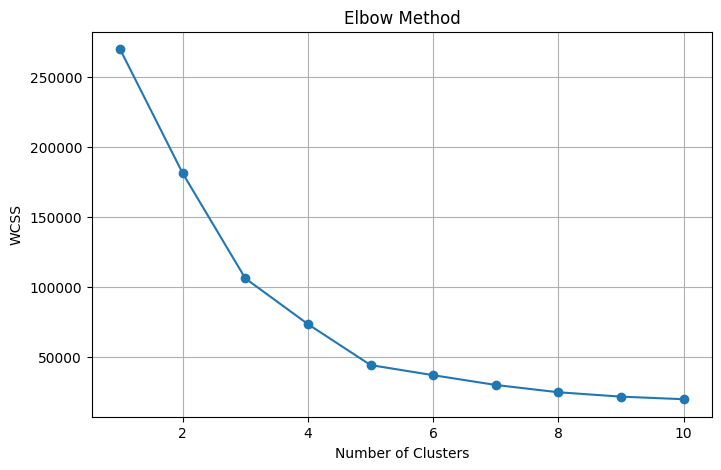

In [61]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

In [62]:
# Apply K-Means clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

df["Cluster"] = kmeans.fit_predict(X)

print("Customer segmentation completed!")
print(df[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head())

Customer segmentation completed!
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4


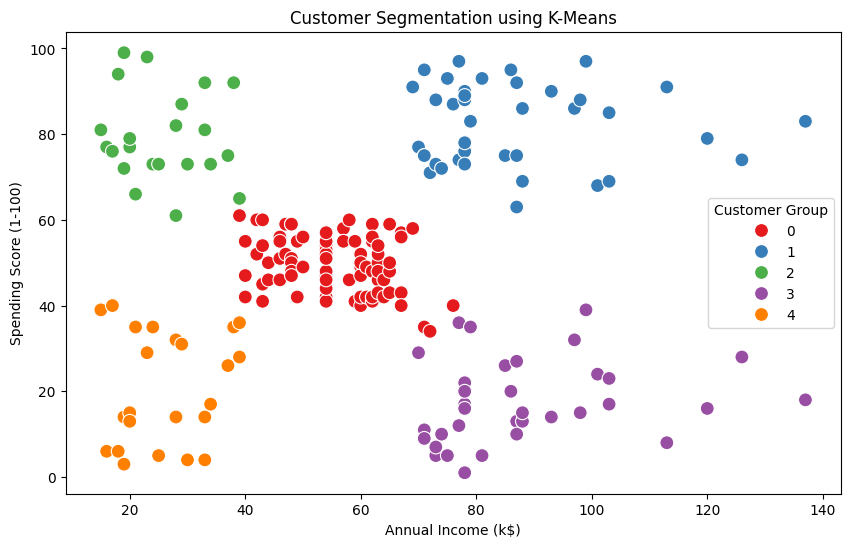

In [63]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="Set1",
    s=100
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Group")
plt.show()

In [64]:
# Analyze each customer group
cluster_analysis = df.groupby("Cluster").agg({
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean",
    "CustomerID": "count"
})

cluster_analysis.rename(
    columns={"CustomerID": "Number of Customers"},
    inplace=True
)

print("Customer Segment Analysis:")
display(cluster_analysis.round(2))

Customer Segment Analysis:


,Annual Income (k$),Spending Score (1-100),Number of Customers
Cluster,,,
0,55.30,49.52,81
1,86.54,82.13,39
2,25.73,79.36,22
3,88.20,17.11,35
4,26.30,20.91,23


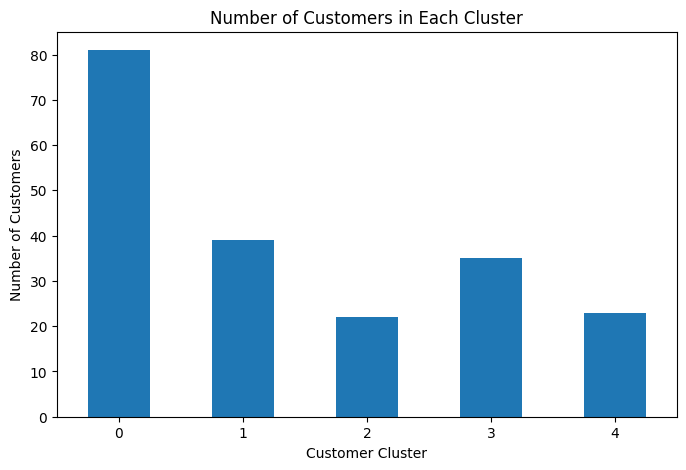

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [65]:
# Count customers in each cluster
cluster_counts = df["Cluster"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
cluster_counts.plot(kind="bar")

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

print(cluster_counts)

## Customer Segmentation — Key Observations

1. Customers are divided into five groups using the K-Means clustering algorithm.
2. Customer groups differ based on annual income and spending score.
3. Some customers have high income and high spending scores.
4. Some customers have high income but low spending scores, which may indicate potential business opportunities.
5. Other groups include customers with lower income and different spending patterns.

## Business Recommendations

1. Offer loyalty rewards to customers with high spending scores.
2. Create targeted promotions to encourage high-income customers with low spending scores to purchase more.
3. Develop affordable offers for customers with lower annual income.
4. Use customer segments to design personalized marketing campaigns.

## Conclusion

Customer segmentation using K-Means helps businesses understand different customer purchasing behaviours. This analysis groups customers based on annual income and spending score, helping businesses improve marketing strategies, customer engagement, and sales opportunities.